# Proposed SA-CPW-GAN Model

**Self-Attentive, Class-Modulated, Projection WGAN-GP with Spectral-Consistency Loss and Adapter-Style Few-Shot Fine-Tuning**

This notebook is created directly from `novel_wgan(1).py` and reorganized into executable Jupyter cells, following the practical workflow of the earlier WGAN notebook.

Implemented components:
- Conditional Batch Normalization (CondBN)
- Self-Attention at 16×16 resolution
- Projection Critic
- Auxiliary Classifier head
- Differentiable Augmentation
- WGAN-GP gradient penalty
- Spectral-consistency loss
- EMA Generator
- Adapter-style few-shot fine-tuning with L2-SP
- Class-wise synthetic image generation
- TSTR evaluation


In [ ]:
# Install dependencies if required
# In Kaggle/Colab, PyTorch is usually already installed.
# Uncomment only if your environment does not have these packages.
# !pip install torch torchvision matplotlib

import os
import copy
import random
import numpy as np
from types import SimpleNamespace

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


## 1. Configuration

Change only the dataset paths below for your experiment.

Expected folder structure:

```text
TRAIN_DIR/
    class_0/
    class_1/
    class_2/

FINETUNE_DIR/
    class_0/
    class_1/
    class_2/

TEST_DIR/
    class_0/
    class_1/
    class_2/
```

`TEST_DIR` must remain a held-out real dataset and is used only for TSTR evaluation.


In [2]:
# ==========================
# CONFIGURATION
# ==========================

TRAIN_DIR = "/kaggle/input/datasets/ashishtalekar1212/stockgan/trainwgan"
FINETUNE_DIR = "/kaggle/input/datasets/ashishtalekar1212/stockgan/SBI2yrf/SBI2yr"
TEST_DIR = None   # Example: "/kaggle/input/stockgan/sbitest"
OUTPUT_DIR = "run_sacpw"

args = SimpleNamespace(
    train_dir=TRAIN_DIR,
    finetune_dir=FINETUNE_DIR,
    test_dir=TEST_DIR,
    out=OUTPUT_DIR,

    img_size=64,
    z_dim=128,
    batch_size=32,
    workers=2,
    lr=1e-4,
    n_critic=5,

    pretrain_iters=10000,
    finetune_iters=3000,

    lambda_gp=10.0,
    lambda_aux=1.0,
    lambda_spec=1.0,
    lambda_sp=100.0,
    aug_strength=1.0,

    n_generate=1000,       # synthetic images per class
    log_every=100,
    sample_every=1000,

    # Ablation switches: set False to disable a component
    attn=True,
    cbn=True,
    proj=True,
    aux=True,
    spec=True,
    aug=True,
    ema=True,
)

os.makedirs(args.out, exist_ok=True)
print("Output directory:", args.out)


Output directory: run_sacpw


## 2. Proposed Building Blocks: Conditional BatchNorm and Self-Attention

In [3]:
class CondBN(nn.Module):
    """BatchNorm whose scale/shift are looked up from the class label."""
    def __init__(self, ch, n_classes, conditional=True):
        super().__init__()
        self.conditional = conditional
        if conditional:
            self.bn = nn.BatchNorm2d(ch, affine=False)
            self.gamma = nn.Embedding(n_classes, ch)
            self.beta = nn.Embedding(n_classes, ch)
            nn.init.ones_(self.gamma.weight); nn.init.zeros_(self.beta.weight)
        else:
            self.bn = nn.BatchNorm2d(ch)

    def forward(self, x, y):
        x = self.bn(x)
        if self.conditional:
            x = x * self.gamma(y)[:, :, None, None] + self.beta(y)[:, :, None, None]
        return x


class SelfAttention(nn.Module):
    """SAGAN-style self-attention; gamma starts at 0 so it begins as identity."""
    def __init__(self, ch):
        super().__init__()
        self.q = nn.Conv2d(ch, max(ch // 8, 1), 1)
        self.k = nn.Conv2d(ch, max(ch // 8, 1), 1)
        self.v = nn.Conv2d(ch, ch // 2, 1)
        self.o = nn.Conv2d(ch // 2, ch, 1)
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        B, C, H, W = x.shape
        q, k, v = self.q(x).flatten(2), self.k(x).flatten(2), self.v(x).flatten(2)
        attn = torch.softmax(q.transpose(1, 2) @ k, dim=-1)          # B,N,N
        out = (v @ attn.transpose(1, 2)).view(B, C // 2, H, W)
        return x + self.gamma * self.o(out)

## 3. Class-Conditional Generator

In [4]:
class Generator(nn.Module):
    def __init__(self, n_classes, z_dim=128, emb_dim=64, f=64, out_ch=1,
                 use_cbn=True, use_attn=True):
        super().__init__()
        self.use_cbn, self.use_attn, self.z_dim = use_cbn, use_attn, z_dim
        # if class modulation is off, fall back to plain concatenation
        self.emb = nn.Embedding(n_classes, emb_dim) if not use_cbn else None
        zin = z_dim + (0 if use_cbn else emb_dim)

        self.l0 = nn.ConvTranspose2d(zin, f * 8, 4, 1, 0, bias=False)      # 4x4
        self.n0 = CondBN(f * 8, n_classes, use_cbn)
        self.l1 = nn.ConvTranspose2d(f * 8, f * 4, 4, 2, 1, bias=False)    # 8x8
        self.n1 = CondBN(f * 4, n_classes, use_cbn)
        self.l2 = nn.ConvTranspose2d(f * 4, f * 2, 4, 2, 1, bias=False)    # 16x16
        self.n2 = CondBN(f * 2, n_classes, use_cbn)
        self.sa = SelfAttention(f * 2) if use_attn else nn.Identity()
        self.l3 = nn.ConvTranspose2d(f * 2, f, 4, 2, 1, bias=False)        # 32x32
        self.n3 = CondBN(f, n_classes, use_cbn)
        self.l4 = nn.ConvTranspose2d(f, out_ch, 4, 2, 1)                   # 64x64

    def forward(self, z, y):
        z = z.view(z.size(0), -1)
        if not self.use_cbn:
            z = torch.cat([z, self.emb(y)], dim=1)
        x = z[:, :, None, None]
        x = F.relu(self.n0(self.l0(x), y))
        x = F.relu(self.n1(self.l1(x), y))
        x = F.relu(self.n2(self.l2(x), y))
        x = self.sa(x)
        x = F.relu(self.n3(self.l3(x), y))
        return torch.tanh(self.l4(x))

## 4. Projection Critic with Auxiliary Classifier

In [5]:
class Critic(nn.Module):
    def __init__(self, n_classes, in_ch=1, f=64, use_attn=True, use_proj=True):
        super().__init__()
        self.use_proj = use_proj
        self.c1 = nn.Conv2d(in_ch, f, 4, 2, 1)                              # 32
        self.c2 = nn.Conv2d(f, f * 2, 4, 2, 1)                              # 16
        self.i2 = nn.InstanceNorm2d(f * 2, affine=True)
        self.sa = SelfAttention(f * 2) if use_attn else nn.Identity()
        self.c3 = nn.Conv2d(f * 2, f * 4, 4, 2, 1)                          # 8
        self.i3 = nn.InstanceNorm2d(f * 4, affine=True)
        self.c4 = nn.Conv2d(f * 4, f * 8, 4, 2, 1)                          # 4
        self.i4 = nn.InstanceNorm2d(f * 8, affine=True)
        self.lin = nn.Linear(f * 8, 1)
        self.proj = nn.Embedding(n_classes, f * 8) if use_proj else None
        self.aux = nn.Linear(f * 8, n_classes)                              # AC head

    def forward(self, x, y):
        h = F.leaky_relu(self.c1(x), 0.2)
        h = F.leaky_relu(self.i2(self.c2(h)), 0.2)
        h = self.sa(h)
        h = F.leaky_relu(self.i3(self.c3(h)), 0.2)
        h = F.leaky_relu(self.i4(self.c4(h)), 0.2)
        h = h.sum(dim=(2, 3))                                               # global sum pool
        score = self.lin(h).squeeze(1)
        if self.use_proj:
            score = score + (self.proj(y) * h).sum(1)
        return score, self.aux(h)

## 5. DiffAugment, WGAN-GP, Spectral Loss, EMA, and Data Loader

In [6]:
def diff_augment(x, strength=1.0):
    """Differentiable translation + brightness + contrast (applied per-sample)."""
    B = x.size(0)
    theta = torch.zeros(B, 2, 3, device=x.device)
    theta[:, 0, 0] = 1; theta[:, 1, 1] = 1
    theta[:, :, 2] = (torch.rand(B, 2, device=x.device) - 0.5) * 0.25 * strength
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode="reflection", align_corners=False)
    x = x + (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.4 * strength
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - m) * (1 + (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.4 * strength) + m
    return x


def gradient_penalty(C, real, fake, y):
    eps = torch.rand(real.size(0), 1, 1, 1, device=real.device)
    xi = (eps * real + (1 - eps) * fake).requires_grad_(True)
    s, _ = C(xi, y)
    g = torch.autograd.grad(s.sum(), xi, create_graph=True)[0]
    return ((g.flatten(1).norm(2, dim=1) - 1) ** 2).mean()


def spectral_loss(fake, real):
    """Match batch-mean log-amplitude spectrum (captures texture / noise / sharpness)."""
    def spec(x):
        f = torch.fft.rfft2(x.squeeze(1), norm="ortho")
        return torch.log1p(f.abs()).mean(0)
    return F.l1_loss(spec(fake), spec(real).detach())


@torch.no_grad()
def ema_update(ema, model, decay=0.999):
    for pe, p in zip(ema.parameters(), model.parameters()):
        pe.mul_(decay).add_(p.detach(), alpha=1 - decay)
    for be, b in zip(ema.buffers(), model.buffers()):
        be.copy_(b)


def infinite(loader):
    while True:
        for batch in loader:
            yield batch


def make_loader(path, size, bs, workers, shuffle=True):
    tf = transforms.Compose([
        transforms.Grayscale(1), transforms.Resize((size, size)),
        transforms.ToTensor(), transforms.Normalize([0.5], [0.5])])
    ds = datasets.ImageFolder(path, transform=tf)
    return ds, DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=workers,
                          drop_last=shuffle, pin_memory=torch.cuda.is_available())

## 6. Proposed SA-CPW-GAN Training Procedure

In [7]:
def train(G, C, G_ema, loader, iters, args, device, tag, fewshot=False):
    # optional few-shot setup: freeze most of the networks, anchor to pretrained weights
    anchor = {}
    if fewshot:
        for n, p in G.named_parameters():
            p.requires_grad = any(k in n for k in ("gamma", "beta", "sa.", "l4"))
            if p.requires_grad:
                anchor[n] = p.detach().clone()
        for n, p in C.named_parameters():
            p.requires_grad = not (n.startswith("c1") or n.startswith("c2") or n.startswith("i2"))
    lr = args.lr * (0.5 if fewshot else 1.0)
    oG = torch.optim.Adam([p for p in G.parameters() if p.requires_grad], lr=lr, betas=(0.0, 0.9))
    oC = torch.optim.Adam([p for p in C.parameters() if p.requires_grad], lr=lr, betas=(0.0, 0.9))
    data = infinite(loader)
    aug = (lambda x: diff_augment(x, args.aug_strength)) if args.aug else (lambda x: x)
    G.train(); C.train()

    for it in range(1, iters + 1):
        # ---- critic ----
        for _ in range(args.n_critic):
            real, y = next(data); real, y = real.to(device), y.to(device)
            z = torch.randn(real.size(0), args.z_dim, device=device)
            with torch.no_grad():
                fake = G(z, y)
            rs, rl = C(aug(real), y)
            fs, _ = C(aug(fake), y)
            gp = gradient_penalty(C, aug(real), aug(fake), y)
            loss_C = fs.mean() - rs.mean() + args.lambda_gp * gp + 1e-3 * (rs ** 2).mean()
            if args.aux:
                loss_C = loss_C + args.lambda_aux * F.cross_entropy(rl, y)
            oC.zero_grad(set_to_none=True); loss_C.backward(); oC.step()

        # ---- generator ----
        z = torch.randn(real.size(0), args.z_dim, device=device)
        fake = G(z, y)
        fs, fl = C(aug(fake), y)
        loss_G = -fs.mean()
        if args.aux:
            loss_G = loss_G + args.lambda_aux * F.cross_entropy(fl, y)
        if args.spec:
            loss_G = loss_G + args.lambda_spec * spectral_loss(fake, real)
        if fewshot and anchor:                                       # L2-SP
            loss_G = loss_G + args.lambda_sp * sum(
                ((p - anchor[n]) ** 2).sum() for n, p in G.named_parameters() if n in anchor)
        oG.zero_grad(set_to_none=True); loss_G.backward(); oG.step()
        if args.ema:
            ema_update(G_ema, G)

        if it % args.log_every == 0:
            print(f"[{tag}] it {it}/{iters}  C {loss_C.item():+.3f}  G {loss_G.item():+.3f}  GP {gp.item():.3f}")
        if it % args.sample_every == 0 or it == iters:
            save_samples(G_ema if args.ema else G, args, device, f"{args.out}/samples/{tag}_{it:06d}.png")
    torch.save({"G": G.state_dict(), "G_ema": G_ema.state_dict(), "C": C.state_dict()},
               f"{args.out}/{tag}.pt")


@torch.no_grad()
def save_samples(G, args, device, path, n_per_class=8):
    was = G.training; G.eval()
    ys = torch.arange(args.n_classes, device=device).repeat_interleave(n_per_class)
    x = G(torch.randn(len(ys), args.z_dim, device=device), ys)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    utils.save_image((x + 1) / 2, path, nrow=n_per_class)
    G.train(was)


@torch.no_grad()
def generate_dataset(G, args, device, n_per_class, class_names):
    G.eval()
    out = os.path.join(args.out, "generated")
    for c, name in enumerate(class_names):
        d = os.path.join(out, name); os.makedirs(d, exist_ok=True)
        for s in range(0, n_per_class, 64):
            k = min(64, n_per_class - s)
            x = G(torch.randn(k, args.z_dim, device=device), torch.full((k,), c, device=device))
            for j in range(k):
                utils.save_image((x[j] + 1) / 2, f"{d}/{name}_{s + j:05d}.png")
    return out

## 7. TSTR Evaluation Network

In [8]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, 1, 1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.f = nn.Sequential(blk(1, 32), blk(32, 64), blk(64, 128), blk(128, 128))
        self.fc = nn.Linear(128 * 4 * 4, n_classes)
    def forward(self, x): return self.fc(self.f(x).flatten(1))


def tstr(train_loader, test_loader, n_classes, device, epochs=10):
    net = SmallCNN(n_classes).to(device)
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    for _ in range(epochs):
        net.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); F.cross_entropy(net(x), y).backward(); opt.step()
    net.eval(); correct = total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            correct += (net(x).argmax(1) == y).sum().item(); total += len(y)
    return correct / max(total, 1)

## 8. Load Training Data and Initialize the Proposed Model

The class labels are discovered automatically from the training folders. A **single class-conditional Generator and Critic** are trained jointly across all classes, as implemented in `novel_wgan(1).py`.


In [9]:
ds, loader = make_loader(
    args.train_dir,
    args.img_size,
    args.batch_size,
    args.workers
)

args.n_classes = len(ds.classes)

print("Classes:", ds.classes)
print("Number of classes:", args.n_classes)
print("Training images:", len(ds))

G = Generator(
    args.n_classes,
    args.z_dim,
    use_cbn=args.cbn,
    use_attn=args.attn
).to(device)

C = Critic(
    args.n_classes,
    use_attn=args.attn,
    use_proj=args.proj
).to(device)

G_ema = copy.deepcopy(G).eval()
for p in G_ema.parameters():
    p.requires_grad = False

print("\nGenerator:")
print(G)
print("\nCritic:")
print(C)

print("\nGenerator parameters:",
      f"{sum(p.numel() for p in G.parameters()):,}")
print("Critic parameters:",
      f"{sum(p.numel() for p in C.parameters()):,}")


Classes: ['class_0', 'class_1', 'class_2']
Number of classes: 3
Training images: 3900

Generator:
Generator(
  (l0): ConvTranspose2d(128, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
  (n0): CondBN(
    (bn): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=False, track_running_stats=True)
    (gamma): Embedding(3, 512)
    (beta): Embedding(3, 512)
  )
  (l1): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (n1): CondBN(
    (bn): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=False, track_running_stats=True)
    (gamma): Embedding(3, 256)
    (beta): Embedding(3, 256)
  )
  (l2): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (n2): CondBN(
    (bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=False, track_running_stats=True)
    (gamma): Embedding(3, 128)
    (beta): Embedding(3, 128)
  )
  (sa): SelfAttention(
    (q): Conv2d(128, 16, kernel_size=(1, 1), stride=(1, 1))
    (k): Conv2

## 9. Pretraining

In [10]:
train(
    G, C, G_ema,
    loader,
    args.pretrain_iters,
    args,
    device,
    tag="pretrain",
    fewshot=False
)

print("Pretraining completed.")
print("Checkpoint:", os.path.join(args.out, "pretrain.pt"))


[pretrain] it 100/10000  C +186.616  G +19.781  GP 19.260
[pretrain] it 200/10000  C +8.115  G +14.230  GP 1.250
[pretrain] it 300/10000  C -5.730  G +10.437  GP 0.358
[pretrain] it 400/10000  C -3.333  G +6.633  GP 0.105
[pretrain] it 500/10000  C -6.074  G +9.136  GP 0.188
[pretrain] it 600/10000  C -2.233  G +4.886  GP 0.027
[pretrain] it 700/10000  C -1.584  G +0.316  GP 0.025
[pretrain] it 800/10000  C -0.696  G +1.444  GP 0.027
[pretrain] it 900/10000  C -2.415  G +3.576  GP 0.046
[pretrain] it 1000/10000  C -0.605  G +1.645  GP 0.019
[pretrain] it 1100/10000  C +0.624  G +2.424  GP 0.017
[pretrain] it 1200/10000  C -1.674  G -0.106  GP 0.009
[pretrain] it 1300/10000  C -0.646  G +1.781  GP 0.007
[pretrain] it 1400/10000  C +0.088  G +1.073  GP 0.004
[pretrain] it 1500/10000  C -0.758  G +4.525  GP 0.034
[pretrain] it 1600/10000  C -0.781  G +3.244  GP 0.031
[pretrain] it 1700/10000  C +0.193  G +0.473  GP 0.015
[pretrain] it 1800/10000  C -0.391  G +4.545  GP 0.024
[pretrain] it

## 10. Adapter-Style Few-Shot Fine-Tuning

During fine-tuning, the implementation freezes most Generator parameters and the early Critic layers. Generator modulation parameters (`gamma`, `beta`), self-attention, and the output layer remain trainable, with L2-SP regularization toward pretrained weights.


In [11]:
if args.finetune_dir:
    fds, floader = make_loader(
        args.finetune_dir,
        args.img_size,
        min(args.batch_size, 32),
        args.workers
    )

    assert fds.classes == ds.classes, (
        "Pretraining and fine-tuning class folders must match. "
        f"Train={ds.classes}, Fine-tune={fds.classes}"
    )

    print("Fine-tuning images:", len(fds))
    print("Classes:", fds.classes)

    # Restart EMA from the pretrained generator, as in novel_wgan(1).py
    G_ema.load_state_dict(G.state_dict())

    train(
        G, C, G_ema,
        floader,
        args.finetune_iters,
        args,
        device,
        tag="finetune",
        fewshot=True
    )

    print("Fine-tuning completed.")
    print("Checkpoint:", os.path.join(args.out, "finetune.pt"))
else:
    print("FINETUNE_DIR is None; skipping few-shot fine-tuning.")


Fine-tuning images: 535
Classes: ['class_0', 'class_1', 'class_2']
[finetune] it 100/3000  C -12.463  G +16.455  GP 0.281
[finetune] it 200/3000  C -18.068  G +19.496  GP 0.318
[finetune] it 300/3000  C -12.929  G +21.777  GP 0.343
[finetune] it 400/3000  C -17.826  G +19.724  GP 0.344
[finetune] it 500/3000  C -14.298  G +19.797  GP 0.381
[finetune] it 600/3000  C -19.169  G +21.931  GP 0.473
[finetune] it 700/3000  C -9.880  G +23.338  GP 0.272
[finetune] it 800/3000  C -18.039  G +24.840  GP 0.559
[finetune] it 900/3000  C -13.903  G +21.802  GP 0.382
[finetune] it 1000/3000  C -13.609  G +23.520  GP 0.315
[finetune] it 1100/3000  C -17.229  G +22.268  GP 0.427
[finetune] it 1200/3000  C -16.280  G +23.029  GP 0.398
[finetune] it 1300/3000  C -13.919  G +22.395  GP 0.511
[finetune] it 1700/3000  C -18.341  G +22.641  GP 0.540
[finetune] it 1800/3000  C -18.389  G +26.367  GP 0.416
[finetune] it 1900/3000  C -19.063  G +21.816  GP 0.461
[finetune] it 2000/3000  C -17.713  G +24.060  

## 11. Generate Class-Wise Synthetic Images

In [12]:
final_G = G_ema if args.ema else G

gen_dir = generate_dataset(
    final_G,
    args,
    device,
    args.n_generate,
    ds.classes
)

print("Synthetic dataset saved to:", gen_dir)
for class_name in ds.classes:
    class_dir = os.path.join(gen_dir, class_name)
    count = len([
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])
    print(f"{class_name}: {count} generated images")


Synthetic dataset saved to: run_sacpw/generated
class_0: 1000 generated images
class_1: 1000 generated images
class_2: 1000 generated images


## 12. Display Generated Samples

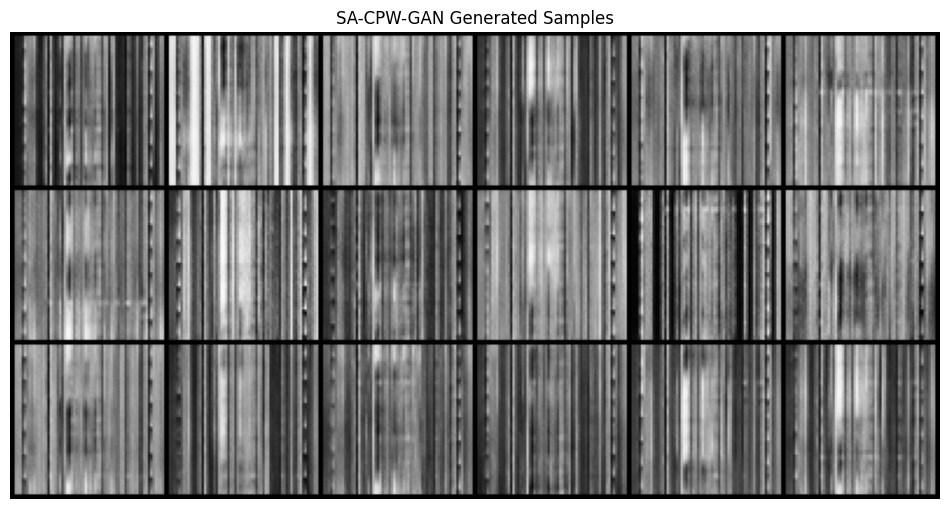

In [13]:
@torch.no_grad()
def show_generated_samples(model, class_names, n_per_class=6):
    model.eval()
    ys = torch.arange(len(class_names), device=device).repeat_interleave(n_per_class)
    z = torch.randn(len(ys), args.z_dim, device=device)
    images = model(z, ys).cpu()
    grid = utils.make_grid((images + 1) / 2, nrow=n_per_class)

    plt.figure(figsize=(12, 2.5 * len(class_names)))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.axis("off")
    plt.title("SA-CPW-GAN Generated Samples")
    plt.show()

show_generated_samples(final_G, ds.classes)


## 13. TSTR: Train on Synthetic, Test on Real

This evaluation trains a small CNN using only the generated dataset and tests it on a held-out **real** test set. The test set must never be used for GAN training or fine-tuning.


In [ ]:
if args.test_dir:
    tf = transforms.Compose([
        transforms.Grayscale(1),
        transforms.Resize((args.img_size, args.img_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5])
    ])

    syn = DataLoader(
        datasets.ImageFolder(gen_dir, transform=tf),
        batch_size=64,
        shuffle=True
    )

    real_test = DataLoader(
        datasets.ImageFolder(args.test_dir, transform=tf),
        batch_size=64,
        shuffle=False
    )

    acc = tstr(syn, real_test, args.n_classes, device)
    print(f"TSTR accuracy (train synthetic -> test real): {acc:.4f}")

    with open(os.path.join(args.out, "tstr.txt"), "w") as f:
        f.write(f"{acc:.4f}\n")
else:
    print("TEST_DIR is None. Set TEST_DIR to a held-out real dataset to run TSTR.")


## 14. Save Final Generator and Critic Weights

In [ ]:
final_checkpoint = os.path.join(args.out, "SA_CPW_GAN_final.pt")

torch.save({
    "G": G.state_dict(),
    "G_ema": G_ema.state_dict(),
    "C": C.state_dict(),
    "classes": ds.classes,
    "n_classes": args.n_classes,
    "z_dim": args.z_dim,
    "img_size": args.img_size
}, final_checkpoint)

print("Saved:", final_checkpoint)


## 15. Optional Ablation Studies

The original `.py` implementation supports component-wise ablation. Before rerunning training, set one or more of these configuration values to `False`:

- `args.attn = False` — remove self-attention
- `args.cbn = False` — remove Conditional BatchNorm
- `args.proj = False` — remove projection conditioning
- `args.aux = False` — remove auxiliary classification loss
- `args.spec = False` — remove spectral-consistency loss
- `args.aug = False` — remove DiffAugment
- `args.ema = False` — use the ordinary Generator rather than EMA Generator

Run each ablation in a different `args.out` directory so checkpoints and generated images are not overwritten.
